# Assignment 2 — Part 1: Thailand Air Quality **Clustering Analysis** (10 คะแนน)

**คู่มือทำจริงทีละขั้น | Dataset: Air_Quality_Dataset (1).xlsx | ปี 2025 | 18 สถานี**

**โจทย์:** เปลี่ยนข้อมูลคุณภาพอากาศรายวันเป็นข้อมูล **Station × Month (216 แถว)** แล้วใช้ K-Means และ Hierarchical (Ward) จัดกลุ่ม จากนั้นอธิบายผลและเสนอแนวทางเฝ้าระวัง

**ข้อกำหนดสำคัญ:** ข้อมูลนี้เป็น *synthetic educational dataset* — ตัวเลขและเกณฑ์ใช้เพื่อการศึกษา ไม่ใช่ผลตรวจวัดจริง

| หัวข้อเกณฑ์ | คะแนน | อยู่ขั้นตอน |
|---|---:|---|
| Preparation & aggregation | 1 | 1–3 |
| Scaling and feature selection | 2 | 4–5 |
| K-Means and K selection | 2 | 6–7 |
| Hierarchical and dendrogram | 2 | 8 |
| Cluster interpretation | 2 | 9–10 |
| Recommendations | 1 | 11 |
| **รวม** | **10** | |

## ก่อนเริ่ม: เปิดโปรแกรมและวางไฟล์ให้ถูกที่

1. เปิด **Google Colab** (`https://colab.research.google.com`) > **Upload notebook** แล้วเลือกไฟล์ `.ipynb` นี้ หรือใช้ Jupyter Notebook / VS Code ก็ได้
2. อัปโหลดไฟล์ Excel `Air_Quality_Dataset (1).xlsx` ผ่านเมนูรูปโฟลเดอร์ (Files) ของ Colab (ถ้าใช้ Jupyter ให้วางไว้ข้างไฟล์ Notebook)
3. กด **Runtime > Run all** (หรือรันทีละช่องด้วย `Shift+Enter`) ตามลำดับตั้งแต่บนลงล่าง
4. เซฟผลเป็น `.ipynb` โดยต้องเหลือ **กราฟ/ตารางผลลัพธ์ในเซลล์** ด้วย (ไม่ใช่แค่โค้ดเปล่า)

หากขึ้น `ModuleNotFoundError` ให้ติดตั้งในช่องโค้ดใหม่ด้วย `%pip install pandas numpy openpyxl scikit-learn scipy matplotlib` แล้วรันใหม่

## ขั้นตอน 1 — นำเข้าไลบรารีและอ่าน Excel (Preparation)

**ทำไมต้องทำ:** Python ต้องมีเครื่องมืออ่านตาราง คำนวณ ทำ clustering และวาดกราฟก่อนเริ่มวิเคราะห์

**อ่านผล:** ถ้าระบุไฟล์ถูกต้อง ต้องเห็นจำนวน **6,570 แถว** และรายชื่อคอลัมน์ รวมถึง `Date`, `Station_ID`, `PM2_5_ug_m3` เป็นต้น

In [1]:
%matplotlib inline
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})


from pathlib import Path

# ใส่ไฟล์ Excel ในโฟลเดอร์เดียวกับ Notebook (หรืออัปโหลดใน Colab)
candidates = [
    Path("Air_Quality_Dataset (1).xlsx"),
    Path("Air_Quality_Dataset.xlsx"),
    Path("/content/Air_Quality_Dataset (1).xlsx"),
    Path("/content/Air_Quality_Dataset.xlsx"),
    Path("/mnt/data/Air_Quality_Dataset (1).xlsx"),
]
file_path = next((p for p in candidates if p.exists()), None)
if file_path is None:
    discovered = sorted(Path(".").glob("Air_Quality_Dataset*.xlsx"))
    file_path = discovered[0] if discovered else None
if file_path is None:
    raise FileNotFoundError("ไม่พบ Excel: กรุณาอัปโหลด Air_Quality_Dataset (1).xlsx แล้วรันใหม่")

print("ใช้ไฟล์:", file_path)

raw = pd.read_excel(file_path, sheet_name="Air_Quality_Data", parse_dates=["Date"])
print("Shape (rows, columns):", raw.shape)
print("Data types:\n", raw.dtypes)
display(raw.head(6))

ใช้ไฟล์: Air_Quality_Dataset (1).xlsx


Shape (rows, columns): (6570, 14)
Data types:
 Date              datetime64[ns]
Station_ID                object
Station_Name              object
Province                  object
Region                    object
Latitude                 float64
Longitude                float64
PM2_5_ug_m3              float64
PM10_ug_m3               float64
AQI                        int64
Temperature_C            float64
Humidity_Pct             float64
Wind_Speed_kmh           float64
Rainfall_mm              float64
dtype: object


,Date,Station_ID,Station_Name,Province,Region,Latitude,Longitude,PM2_5_ug_m3,PM10_ug_m3,AQI,Temperature_C,Humidity_Pct,Wind_Speed_kmh,Rainfall_mm
0,2025-01-01,BKK01,Bangkok Central,Bangkok,Central,13.7563,100.5018,59.7,83.9,118,23.7,70.6,7.9,0.0
1,2025-01-01,NPT01,Nakhon Pathom,Nakhon Pathom,Central,13.8199,100.0622,25.3,41.9,46,26.0,79.8,12.8,0.0
2,2025-01-01,AYA01,Ayutthaya,Phra Nakhon Si Ayutthaya,Central,14.3532,100.5689,22.6,43.5,45,25.3,80.8,8.5,1.3
3,2025-01-01,SKN01,Samut Sakhon,Samut Sakhon,Central,13.5475,100.2744,36.4,57.2,75,24.4,74.2,9.2,0.0
4,2025-01-01,CNX01,Chiang Mai City,Chiang Mai,North,18.7883,98.9853,28.6,37.6,59,22.1,72.5,10.0,1.0
5,2025-01-01,CRI01,Chiang Rai City,Chiang Rai,North,19.9105,99.8406,41.0,57.5,81,22.1,81.8,0.5,0.0


## ขั้นตอน 2 — ตรวจสอบข้อมูลสูญหาย / ซ้ำ / ช่วงเวลา (Preparation)

**เกณฑ์ที่ต้องตอบ**: มีค่า missing หรือไม่? อยู่คอลัมน์อะไร? มีแถวซ้ำตาม `Station_ID + Date` หรือไม่? มีข้อมูลครบ 18 สถานี 365 วันหรือไม่?

**ผลจากไฟล์ที่ส่งมา:** `Humidity_Pct` ขาด **37** ค่า, `Wind_Speed_kmh` ขาด **30** ค่า; ไม่พบข้อมูลซ้ำตามสถานีและวัน

การสั่ง `df.isna().sum()` คือการนับช่องว่างของแต่ละคอลัมน์ ไม่ได้แปลว่าข้อมูลทั้งแถวหายไป

In [2]:
print("จำนวนข้อมูลที่ขาดหายแยกตามคอลัมน์:")
display(raw.isna().sum().to_frame("Missing_Count"))
print("แถวซ้ำทั้งแถว:", raw.duplicated().sum())
print("คีย์ Station_ID + Date ซ้ำ:", raw.duplicated(subset=["Station_ID", "Date"]).sum())
print("วันที่เริ่ม-สิ้นสุด:", raw["Date"].min().date(), "ถึง", raw["Date"].max().date())
print("จำนวนสถานี:", raw["Station_ID"].nunique())
print("จำนวนวันที่ไม่ซ้ำ:", raw["Date"].nunique())
print("จำนวนข้อมูลแต่ละภูมิภาค:")
display(raw.groupby("Region").agg(Stations=("Station_ID", "nunique"), Rows=("Date", "size")))
assert raw["Station_ID"].nunique() == 18
assert raw["Date"].nunique() == 365

จำนวนข้อมูลที่ขาดหายแยกตามคอลัมน์:


,Missing_Count
Date,0
Station_ID,0
Station_Name,0
Province,0
Region,0
Latitude,0
Longitude,0
PM2_5_ug_m3,0
PM10_ug_m3,0
AQI,0


แถวซ้ำทั้งแถว: 0
คีย์ Station_ID + Date ซ้ำ: 0
วันที่เริ่ม-สิ้นสุด: 2025-01-01 ถึง 2025-12-31
จำนวนสถานี: 18
จำนวนวันที่ไม่ซ้ำ: 365
จำนวนข้อมูลแต่ละภูมิภาค:


,Stations,Rows
Region,,
Central,4,1460
East,3,1095
North,4,1460
Northeast,4,1460
South,3,1095


## ขั้นตอน 3 — ทำความสะอาดและรวมข้อมูลเป็น Station × Month (1 คะแนน)

**วิธีจัดการ Missing:** แทนค่าความชื้นและความเร็วลมที่หายด้วย **มัธยฐานของสถานีเดียวกัน** เพื่อรักษาลักษณะของแต่ละสถานีไว้ และมี global median สำรองกรณีทั้งสถานีหายทั้งหมด

**วิธี Aggregate:** เพิ่มคอลัมน์ `Month` จาก `Date` แล้ว `groupby()` ตาม `Station_ID`, `Station_Name`, `Province`, `Region` และ `Month` โดยคำนวณ **mean** ของ 6 ตัวแปรในแต่ละเดือน

**จำนวนที่คาดหวัง:** 18 สถานี × 12 เดือน = **216 แถว**; 1 แถวแทนค่าเฉลี่ยของสถานีหนึ่งในหนึ่งเดือน

*หมายเหตุ:* ไม่ตัดค่า PM10 สูงผิดปกติเพียงเพราะค่าสูง เนื่องจากโจทย์ไม่ได้ให้เกณฑ์ยืนยันว่าเป็นข้อมูลเสีย

In [3]:
df = raw.sort_values(["Station_ID", "Date"]).drop_duplicates(["Station_ID", "Date"]).copy()
for col in ["Humidity_Pct", "Wind_Speed_kmh"]:
    station_median = df.groupby("Station_ID")[col].transform("median")
    df[col] = df[col].fillna(station_median).fillna(df[col].median())

df["Month"] = df["Date"].dt.month
cluster_features = [
    "PM2_5_ug_m3", "PM10_ug_m3", "Temperature_C",
    "Humidity_Pct", "Wind_Speed_kmh", "Rainfall_mm"
]
monthly = (df.groupby(["Station_ID", "Station_Name", "Province", "Region", "Month"], as_index=False)
             [cluster_features].mean()
             .sort_values(["Station_ID", "Month"]).reset_index(drop=True))
print("Missing หลังทำความสะอาด:", df[cluster_features].isna().sum().to_dict())
print("Station × Month shape:", monthly.shape, "(คาดหวัง 216 แถว)")
print("จำนวนคู่สถานี-เดือน:", monthly[["Station_ID", "Month"]].drop_duplicates().shape[0])
assert len(monthly) == 18 * 12 == 216, "ต้องได้ 216 แถว"
display(monthly.head(10).round(2))

Missing หลังทำความสะอาด: {'PM2_5_ug_m3': 0, 'PM10_ug_m3': 0, 'Temperature_C': 0, 'Humidity_Pct': 0, 'Wind_Speed_kmh': 0, 'Rainfall_mm': 0}
Station × Month shape: (216, 11) (คาดหวัง 216 แถว)
จำนวนคู่สถานี-เดือน: 216


,Station_ID,Station_Name,Province,Region,Month,PM2_5_ug_m3,PM10_ug_m3,Temperature_C,Humidity_Pct,Wind_Speed_kmh,Rainfall_mm
0,AYA01,Ayutthaya,Phra Nakhon Si Ayutthaya,Central,1,31.88,52.01,25.77,73.58,8.36,0.33
1,AYA01,Ayutthaya,Phra Nakhon Si Ayutthaya,Central,2,35.15,56.15,27.39,71.69,7.21,0.30
2,AYA01,Ayutthaya,Phra Nakhon Si Ayutthaya,Central,3,25.98,44.22,29.04,68.75,8.80,0.14
3,AYA01,Ayutthaya,Phra Nakhon Si Ayutthaya,Central,4,16.62,31.31,31.34,66.18,7.57,0.58
4,AYA01,Ayutthaya,Phra Nakhon Si Ayutthaya,Central,5,11.54,27.48,32.37,60.48,8.19,2.18
5,AYA01,Ayutthaya,Phra Nakhon Si Ayutthaya,Central,6,9.79,23.13,33.11,61.02,8.43,2.19
6,AYA01,Ayutthaya,Phra Nakhon Si Ayutthaya,Central,7,11.72,24.93,32.21,60.97,7.48,2.50
7,AYA01,Ayutthaya,Phra Nakhon Si Ayutthaya,Central,8,8.67,23.29,31.48,66.24,8.43,3.11
8,AYA01,Ayutthaya,Phra Nakhon Si Ayutthaya,Central,9,10.79,23.47,28.25,69.49,8.13,2.99
9,AYA01,Ayutthaya,Phra Nakhon Si Ayutthaya,Central,10,13.25,29.14,26.36,72.95,7.30,1.80


## ขั้นตอน 4 — เลือกตัวแปร clustering ให้ครบ 6 ตัว (Scaling and feature selection, 2 คะแนน)

**เราเลือก** PM2.5, PM10, Temperature, Humidity, Wind Speed, Rainfall — เป็นตัวชี้วัดมลพิษ **2** ตัว + ตัวแปรสภาพอากาศ **4** ตัว

| ชื่อตัวแปร | ความหมาย | เหตุผลที่ใช้ |
|---|---|---|
| `PM2_5_ug_m3` | ฝุ่น PM2.5 | ประเมินมลพิษฝุ่นละเอียด |
| `PM10_ug_m3` | ฝุ่น PM10 | ประเมินฝุ่นขนาดใหญ่ขึ้น |
| `Temperature_C` | อุณหภูมิ | แยกสภาพอากาศร้อน/เย็น |
| `Humidity_Pct` | ความชื้น | แยกความชื้นในบรรยากาศ |
| `Wind_Speed_kmh` | ความเร็วลม | ปัจจัยเกี่ยวกับการกระจายของฝุ่น |
| `Rainfall_mm` | ปริมาณฝน | ปัจจัยการชะล้างฝุ่น |

**ไม่เลือก** `AQI` เพราะเป็นตัวชี้วัดภาพรวมซึ่งอาจซ้ำซ้อนกับมลพิษฝุ่น และไม่ใช้ชื่อสถานี/จังหวัด/ภูมิภาคเป็นระยะทางตัวเลขโดยตรง (โจทย์ให้ผู้ทำเลือก 6 ตัวแปรเอง ไม่ได้บังคับรายชื่อสำหรับ clustering)

## ขั้นตอน 5 — เติมค่าว่างและ Standardization (Scaling and feature selection, 2 คะแนน)

**ปัญหา:** หน่วยของข้อมูลไม่เท่ากัน เช่น ความชื้นเฉลี่ย ~70 แต่ฝนเฉลี่ย ~1–3 หากคำนวณระยะทางตรง ๆ ตัวแปรที่มีสเกลใหญ่จะมีอิทธิพลมากกว่า

**วิธี:** `SimpleImputer(median)` เติมค่าว่างที่อาจเหลือในข้อมูลรายเดือน แล้วใช้ `StandardScaler()` แปลงค่าเป็น Z-score โดยสูตร

\[ z=\frac{x-\mu}{\sigma} \]

**อ่านผล:** ตัวแปรแต่ละตัวในข้อมูลใหม่จะมีค่าเฉลี่ยใกล้ **0** และส่วนเบี่ยงเบนมาตรฐานใกล้ **1**

In [4]:
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
X_imputed = imputer.fit_transform(monthly[cluster_features])
X_scaled = scaler.fit_transform(X_imputed)
scaled_df = pd.DataFrame(X_scaled, columns=cluster_features)
print("ขนาดข้อมูลมาตรฐาน:", X_scaled.shape)
display(pd.DataFrame({
    "Feature": cluster_features,
    "Mean_after_scaling": scaled_df.mean().to_numpy(),
    "Std_after_scaling": scaled_df.std(ddof=0).to_numpy()
}).round(4))

ขนาดข้อมูลมาตรฐาน: (216, 6)


,Feature,Mean_after_scaling,Std_after_scaling
0,PM2_5_ug_m3,0.0,1.0
1,PM10_ug_m3,-0.0,1.0
2,Temperature_C,0.0,1.0
3,Humidity_Pct,-0.0,1.0
4,Wind_Speed_kmh,0.0,1.0
5,Rainfall_mm,-0.0,1.0


## ขั้นตอน 6 — ทดลอง K-Means ตั้งแต่ K = 2 ถึง 6 (2 คะแนน)

**K-Means** จัดข้อมูลที่คล้ายกันให้อยู่กลุ่มเดียวกัน โดยใช้ระยะห่างจาก centroid (ค่าเฉลี่ยศูนย์กลางกลุ่ม)

ต้องทดลอง **5 ค่า** คือ `K = 2, 3, 4, 5, 6` แล้วประเมินด้วยสองเกณฑ์:

- **Elbow Method (Inertia / WCSS):** ยิ่งต่ำยิ่งดี แต่ดูจุดที่การลดเริ่มน้อยลง (ไม่ใช่เลือก K สูงสุดเสมอ)
- **Silhouette Score:** ช่วง -1 ถึง 1 ยิ่งสูงยิ่งแสดงว่าจุดในกลุ่มเดียวกันคล้ายกันและห่างจากกลุ่มอื่น

ใช้ `random_state=42` ให้ทำซ้ำได้ และ `n_init=20` เพื่อทดสอบจุดเริ่มต้นหลายครั้ง

,K,Inertia_WCSS,Silhouette_Score
0,2,891.8458,0.2837
1,3,638.1664,0.3142
2,4,485.5281,0.3229
3,5,384.0205,0.3516
4,6,333.9041,0.3489


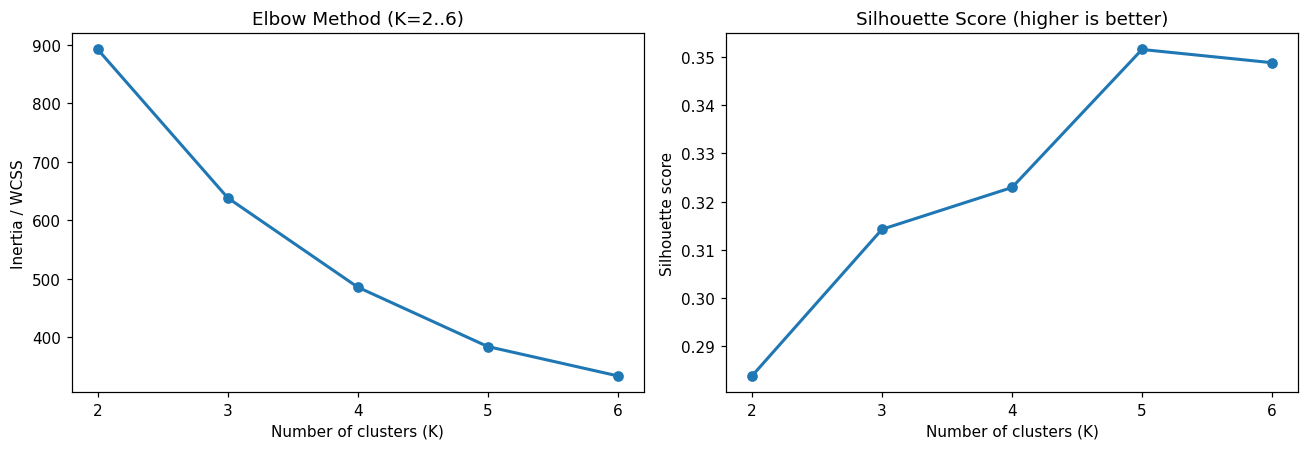

In [5]:
results = []
for k in range(2, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_scaled)
    results.append({
        "K": k,
        "Inertia_WCSS": model.inertia_,
        "Silhouette_Score": silhouette_score(X_scaled, labels)
    })
cluster_metrics = pd.DataFrame(results)
display(cluster_metrics.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(cluster_metrics["K"], cluster_metrics["Inertia_WCSS"], "o-", lw=2)
axes[0].set(title="Elbow Method (K=2..6)", xlabel="Number of clusters (K)", ylabel="Inertia / WCSS")
axes[0].set_xticks(range(2, 7))
axes[1].plot(cluster_metrics["K"], cluster_metrics["Silhouette_Score"], "o-", lw=2)
axes[1].set(title="Silhouette Score (higher is better)", xlabel="Number of clusters (K)", ylabel="Silhouette score")
axes[1].set_xticks(range(2, 7))
plt.tight_layout()
plt.show()

## ขั้นตอน 7 — เลือก K ที่เหมาะสมและติดป้าย Cluster (2 คะแนน)

**หลักฐานจากชุดข้อมูลนี้:** Silhouette Score สูงสุดที่ **K = 5 (~0.352)** มากกว่า K=4 (~0.323) และ K=6 (~0.349) ขณะที่ Inertia ลดต่อเนื่องและเริ่มมีผลตอบแทนลดลง

**คำอธิบายใส่รายงาน:** “เลือก K=5 เพราะมี Silhouette Score สูงสุดในช่วงที่ทดลอง และให้กลุ่มมีรายละเอียดเพียงพอโดยไม่เพิ่มจำนวนกลุ่มเกินจำเป็น ทั้งนี้ Elbow ไม่ได้มีจุดหักที่คมชัด จึงใช้ Silhouette ประกอบการตัดสินใจ”

**คำเตือน:** เลข cluster 1–5 เป็นเพียง **ชื่อกลุ่ม** ไม่ได้แปลว่า 5 อันตรายกว่า 1

In [6]:
best_k = int(cluster_metrics.loc[cluster_metrics["Silhouette_Score"].idxmax(), "K"])
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=20)
monthly["KMeans_Cluster"] = kmeans.fit_predict(X_scaled) + 1
print("K ที่เลือก:", best_k)
print("จำนวน Station-Month ในแต่ละกลุ่ม:")
display(monthly["KMeans_Cluster"].value_counts().sort_index().rename("Count").to_frame())
assert best_k == 5, "ผลไม่ตรงค่าตัวอย่าง โปรดตรวจข้อมูลหรือเวอร์ชันโปรแกรม"

K ที่เลือก: 5
จำนวน Station-Month ในแต่ละกลุ่ม:


,Count
KMeans_Cluster,
1,34
2,46
3,34
4,37
5,65


## ขั้นตอน 8 — Hierarchical Clustering แบบ Ward และ Dendrogram (2 คะแนน)

- **Hierarchical Clustering:** เริ่มจากแต่ละจุดเป็นกลุ่มเดี่ยว แล้วค่อยรวมกลุ่มที่ใกล้กัน
- **Ward's Method:** เลือกรวมกลุ่มที่ทำให้ความแปรปรวนภายในกลุ่มเพิ่มน้อยที่สุด (เหมาะกับ Euclidean distance บนข้อมูลที่ Standardize แล้ว)
- **Dendrogram:** ต้นไม้ที่แสดงลำดับการรวมกลุ่ม ถ้าเส้นเชื่อมอยู่สูงแสดงว่ากลุ่มต่างกันมากขึ้น

กราฟแรกแสดงโครงสร้างทั้ง **216 จุด** และกราฟที่สองย่อเหลือการรวมกลุ่มระดับบนเพื่อให้อ่านง่ายขึ้น

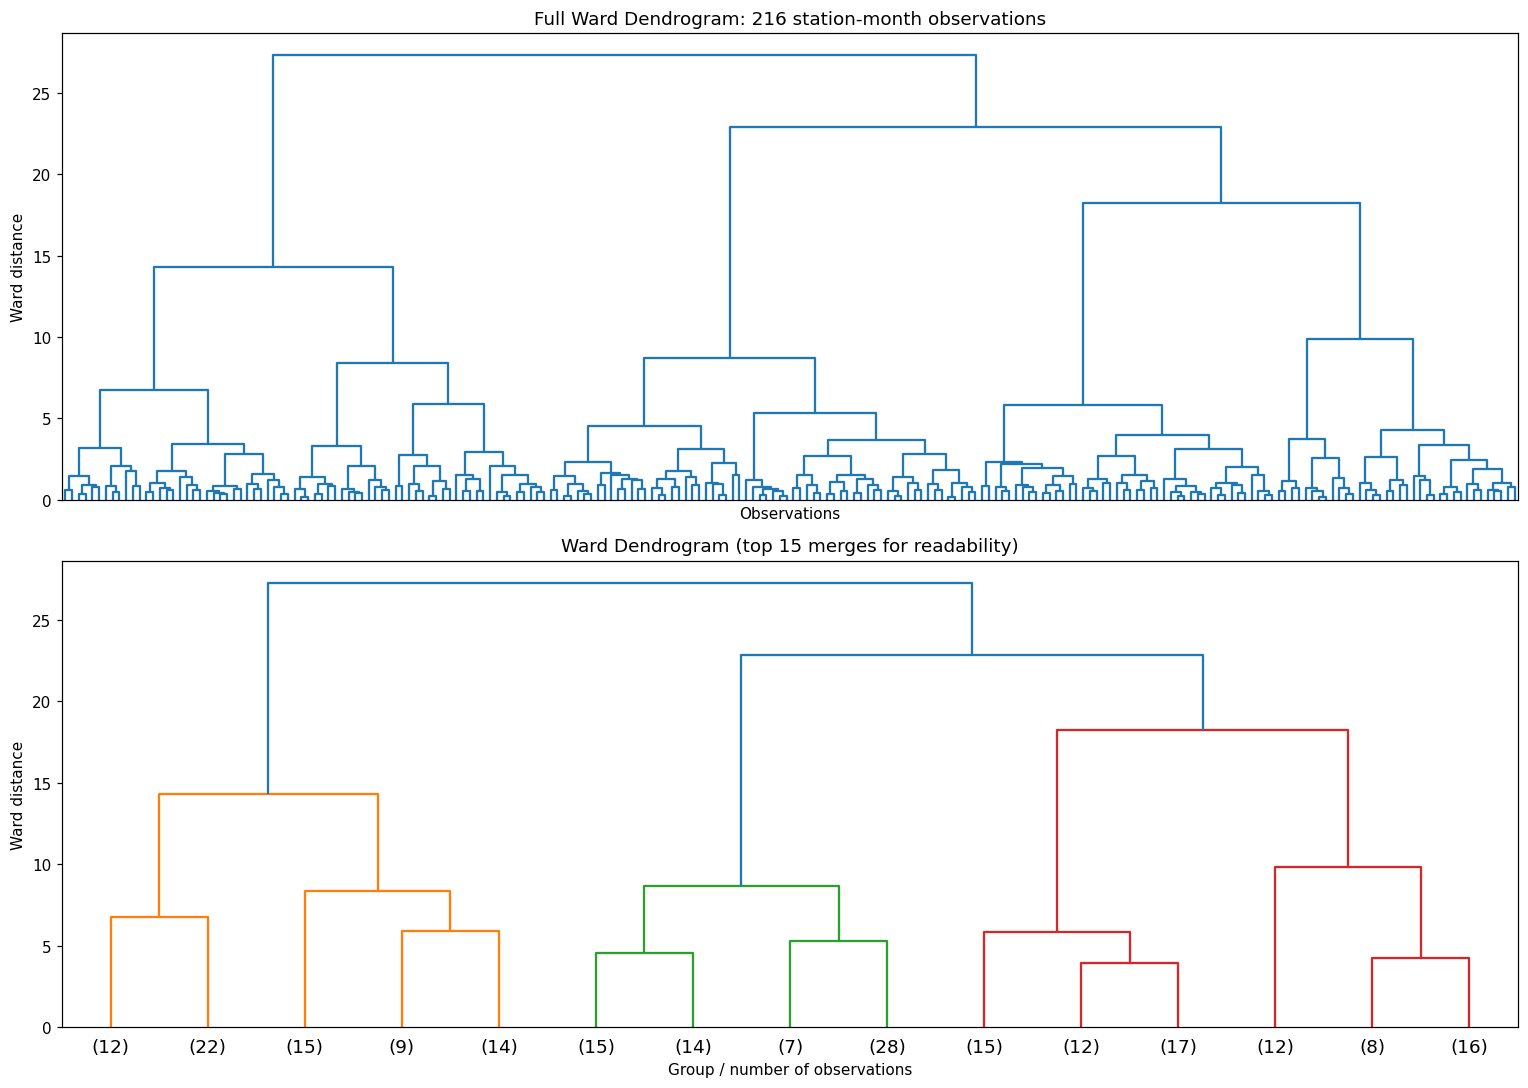

จำนวนรายการแต่ละกลุ่ม Ward:


,Count
Ward_Cluster,
1,36
2,38
3,64
4,44
5,34


In [7]:
ward_labels = AgglomerativeClustering(n_clusters=best_k, linkage="ward").fit_predict(X_scaled)
monthly["Ward_Cluster"] = ward_labels + 1
Z = linkage(X_scaled, method="ward", metric="euclidean")

fig, axes = plt.subplots(2, 1, figsize=(14, 10))
dendrogram(Z, no_labels=True, ax=axes[0], color_threshold=0)
axes[0].set(title="Full Ward Dendrogram: 216 station-month observations", xlabel="Observations", ylabel="Ward distance")
dendrogram(Z, truncate_mode="lastp", p=15, show_leaf_counts=True, ax=axes[1])
axes[1].set(title="Ward Dendrogram (top 15 merges for readability)", xlabel="Group / number of observations", ylabel="Ward distance")
plt.tight_layout()
plt.show()
print("จำนวนรายการแต่ละกลุ่ม Ward:")
display(monthly["Ward_Cluster"].value_counts().sort_index().to_frame("Count"))

## ขั้นตอน 9 — ตาราง Cluster Profile: ค่ากลาง 6 ตัวแปร (2 คะแนน)

ต้องจัดทำ **ค่าเฉลี่ยแบบหน่วยจริง** ของทั้ง 6 ตัวแปร ไม่ใช่แค่ค่าที่ผ่าน StandardScaler เพื่อให้ตีความเป็น PM2.5 µg/m³ และปริมาณฝน mm ได้

เพิ่ม `N` เป็นจำนวนคู่สถานี–เดือนของแต่ละกลุ่ม และทำกราฟ heatmap ช่วยเปรียบเทียบ แต่ค่าตัวเลขในตารางข้างล่างคือหลักฐานหลัก

K-Means Cluster Profile (average of original units):


,N,PM2_5_ug_m3,PM10_ug_m3,Temperature_C,Humidity_Pct,Wind_Speed_kmh,Rainfall_mm
KMeans_Cluster,,,,,,,
1,34,6.79,20.79,30.51,72.41,9.97,3.39
2,46,17.09,33.91,24.73,72.54,7.90,1.12
3,34,43.70,66.86,26.72,69.41,7.95,0.38
4,37,10.31,25.35,25.94,82.20,10.06,1.46
5,65,15.46,31.73,30.71,62.00,8.09,2.17


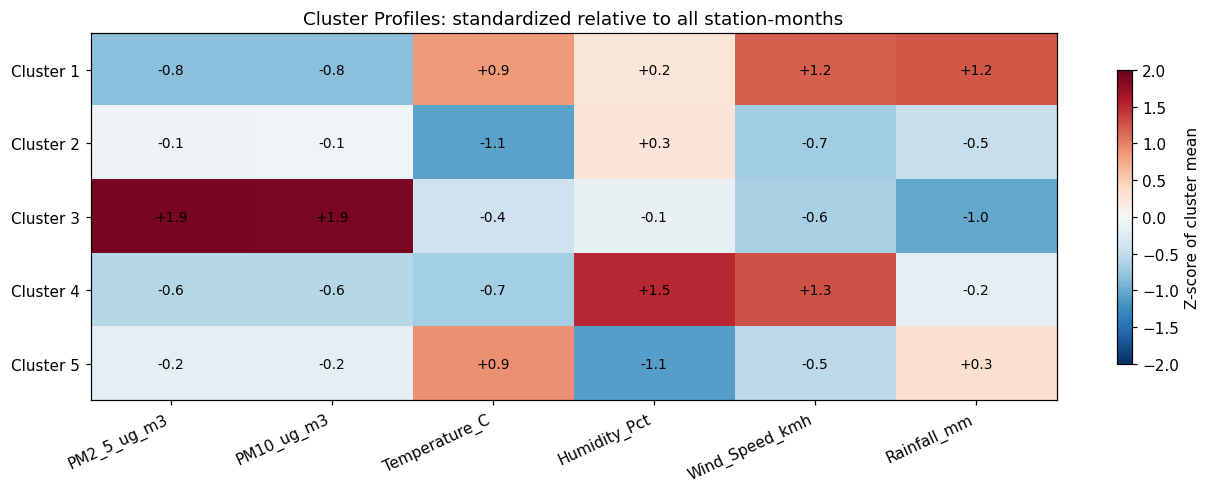

In [8]:
profile = monthly.groupby("KMeans_Cluster").agg(
    N=("Station_ID", "size"),
    **{col: (col, "mean") for col in cluster_features}
).sort_index()
print("K-Means Cluster Profile (average of original units):")
display(profile.round(2))

# Heatmap ใช้ค่า Z-score ของค่าเฉลี่ยแต่ละกลุ่ม เพื่อเปรียบเทียบตัวแปรต่างหน่วย
means_z = (profile[cluster_features] - monthly[cluster_features].mean()) / monthly[cluster_features].std(ddof=0)
fig, ax = plt.subplots(figsize=(12, 4.6))
img = ax.imshow(means_z.to_numpy(), aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2)
ax.set_xticks(range(len(cluster_features)), labels=cluster_features, rotation=25, ha="right")
ax.set_yticks(range(best_k), labels=[f"Cluster {i}" for i in profile.index])
for i in range(best_k):
    for j in range(len(cluster_features)):
        ax.text(j, i, f"{means_z.iloc[i, j]:+.1f}", ha="center", va="center", fontsize=9)
ax.set_title("Cluster Profiles: standardized relative to all station-months")
fig.colorbar(img, ax=ax, label="Z-score of cluster mean", shrink=.8)
plt.tight_layout()
plt.show()

## ขั้นตอน 10 — เปรียบเทียบ K-Means กับ Ward และตีความกลุ่ม (2 คะแนน)

**อย่าเทียบหมายเลขกลุ่มตรง ๆ** เพราะ K-Means cluster 1 ไม่จำเป็นต้องเหมือน Ward cluster 1

ใช้ `Adjusted Rand Index (ARI)` ตรวจสอบว่าการจับคู่สมาชิกคล้ายกันมากเพียงใด:
- ใกล้ 1 = จัดกลุ่มสอดคล้องกันมาก
- ใกล้ 0 = ไม่ดีกว่าความสอดคล้องแบบสุ่มตามหลักการของดัชนี

ชุดข้อมูลนี้ ARI ประมาณ **0.892** แสดงว่า 2 วิธีเห็นโครงสร้างข้อมูลค่อนข้างสอดคล้องกัน แม้สมาชิกบางรายการจะอยู่ต่างกลุ่ม

เพิ่มตาราง Region และ Month เพื่อเชื่อมความหมายของกลุ่มกับพื้นที่และฤดูกาล

Adjusted Rand Index (ARI): 0.8919
Cross-tab KMeans vs Ward (เลขกลุ่มไม่ต้องตรงกัน):


Ward,1,2,3,4,5
KMeans,,,,,
1,0,32,2,0,0
2,2,0,0,44,0
3,34,0,0,0,0
4,0,3,0,0,34
5,0,3,62,0,0


Region × Cluster:


Region,Central,East,North,Northeast,South
KMeans_Cluster,,,,,
1,1,14,0,1,18
2,13,0,17,16,0
3,11,0,15,8,0
4,0,19,0,0,18
5,23,3,16,23,0


Month × Cluster:


Month,1,2,3,4,5,6,7,8,9,10,11,12
KMeans_Cluster,,,,,,,,,,,,
1,0,0,0,4,5,6,6,6,7,0,0,0
2,5,0,1,0,0,0,0,0,4,12,12,12
3,7,12,11,4,0,0,0,0,0,0,0,0
4,6,6,6,0,0,0,0,0,1,6,6,6
5,0,0,0,10,13,12,12,12,6,0,0,0


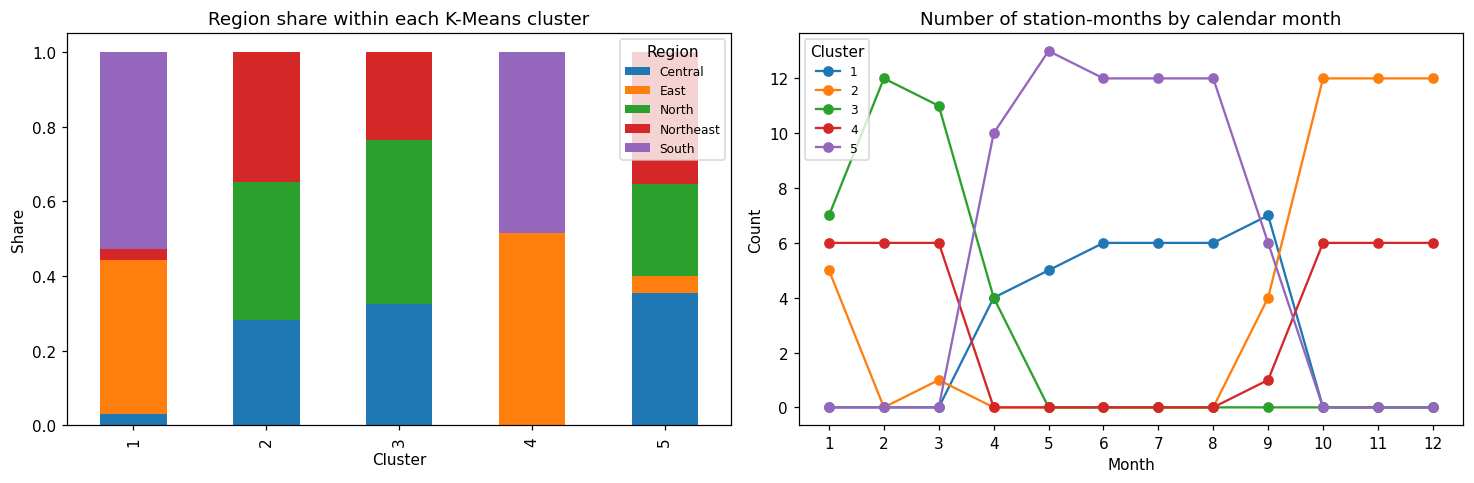

In [9]:
ari = adjusted_rand_score(monthly["KMeans_Cluster"], monthly["Ward_Cluster"])
print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print("Cross-tab KMeans vs Ward (เลขกลุ่มไม่ต้องตรงกัน):")
display(pd.crosstab(monthly["KMeans_Cluster"], monthly["Ward_Cluster"],
                    rownames=["KMeans"], colnames=["Ward"]))
print("Region × Cluster:")
region_tab = pd.crosstab(monthly["KMeans_Cluster"], monthly["Region"])
display(region_tab)
print("Month × Cluster:")
month_tab = pd.crosstab(monthly["KMeans_Cluster"], monthly["Month"])
display(month_tab)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))
region_tab.div(region_tab.sum(axis=1), axis=0).plot(kind="bar", stacked=True, ax=axes[0])
axes[0].set(title="Region share within each K-Means cluster", ylabel="Share", xlabel="Cluster")
axes[0].legend(title="Region", fontsize=8)
month_tab.T.plot(ax=axes[1], marker="o")
axes[1].set(title="Number of station-months by calendar month", ylabel="Count", xlabel="Month")
axes[1].set_xticks(range(1, 13))
axes[1].legend(title="Cluster", fontsize=8)
plt.tight_layout()
plt.show()

## ขั้นตอน 11 — เขียน Insights อย่างน้อย 3 และ Recommendations อย่างน้อย 2 (1 คะแนน)

### คำตอบสรุปที่สามารถปรับใช้ในรายงาน

**Insight 1: กลุ่มมลพิษสูงชัดเจน (K-Means Cluster 3)** 34 station-month มี PM2.5 เฉลี่ยประมาณ **43.70 µg/m³**, PM10 **66.86 µg/m³** และฝนเพียง **0.38 mm** กลุ่มนี้เกิดมากใน **ก.พ.–มี.ค.** และมีข้อมูลจาก North 15, Central 11, Northeast 8 station-month โดย *จำนวนครั้งที่พบในกลุ่ม* ไม่ใช่จำนวนสถานีที่ไม่ซ้ำ

**Insight 2: กลุ่มอากาศสะอาดในช่วงอุ่นและฝนมาก (Cluster 1)** 34 station-month มี PM2.5 เฉลี่ยเพียง **6.79 µg/m³** และฝน **3.39 mm** ส่วนใหญ่เป็น East/South (14/18 station-month ตามลำดับ) สอดคล้องกับความแตกต่างตามภูมิภาคและฤดูกาลของข้อมูลสังเคราะห์นี้

**Insight 3: ไม่ใช่ PM2.5 อย่างเดียวที่แยกกลุ่ม** Cluster 4 มีความชื้นเฉลี่ย ~**82.20%** และลม ~**10.06 km/h** ขณะที่ Cluster 5 มีอุณหภูมิสูง ~**30.71°C** แต่ความชื้นต่ำ ~**62.00%** จึงเห็นกลุ่มสภาพอากาศที่แตกต่างกันแม้ระดับฝุ่นไม่สูงเท่ากลุ่ม 3

**Insight 4 (เสริม):** K-Means และ Ward มี **ARI ≈ 0.892** แสดงว่าผลจัดกลุ่มสอดคล้องกันสูง แต่ไม่ได้หมายความว่าสองวิธีตรงกันทุกจุด

### ข้อเสนอแนะเชิงปฏิบัติ

1. **เฝ้าระวังเข้มข้นในช่วงกุมภาพันธ์–เมษายน** ของสถานีที่เข้า Cluster 3 โดยเพิ่มความถี่การสรุปค่าฝุ่นและระบบแจ้งเตือนเมื่อค่าที่วัดได้สูงผิดปกติ เนื่องจากข้อมูลแสดงฝุ่นระดับสูงในช่วงนี้
2. **จัดมาตรการตามลักษณะของแต่ละกลุ่ม** ไม่ใช้เกณฑ์การติดตามเหมือนกันทั้งหมด: Cluster 1/4 ติดตามแนวโน้มตามฤดูกาล ส่วน Cluster 3 เน้นแผนแจ้งเตือนเชิงรุกและสื่อสารความเสี่ยงรายวัน
3. **ตรวจสอบข้อมูลก่อนใช้งานจริง** เพราะชุดข้อมูลเป็นข้อมูลสังเคราะห์ การจัดกลุ่มไม่ใช่ข้อสรุปเรื่องสาเหตุของมลพิษ และไม่ควรนำไปสรุปสภาพอากาศจริงโดยไม่มีข้อมูลยืนยัน

> ถ้าต้องการความถูกต้องเมื่อเปลี่ยนค่าพารามิเตอร์หรือปรับไฟล์ ให้ใช้ตารางและกราฟที่รันได้จริงเป็นหลัก ไม่คัดลอกตัวเลขนี้โดยไม่ตรวจสอบ

## ขั้นตอน 12 — ตรวจความครบถ้วนก่อนส่ง และบันทึกผลลัพธ์

**เช็กลิสต์ Part 1 (10 คะแนน):**

- [x] ตรวจ missing/duplicate พร้อมวิธีทำความสะอาดและ Aggregate เป็น 216 แถว
- [x] เลือก 6 ตัวแปรพร้อมเหตุผลและ StandardScaler
- [x] ทดลอง K=2–6 มีกราฟ Elbow + Silhouette และเหตุผลเลือก K
- [x] Hierarchical แบบ Ward พร้อม Dendrogram
- [x] Cluster Profile 6 ตัวแปร + เปรียบเทียบ 2 วิธี + แปลผล
- [x] Insights ≥3 และ Recommendations ≥2

**ถ้าส่งแบบ Notebook:** อย่าลืมกด `Run all` ก่อนดาวน์โหลด `.ipynb` และตรวจว่ากราฟอยู่ใน Output ไม่ใช่โค้ดอย่างเดียว

In [10]:
# สรุปตรวจอัตโนมัติ
checks = {
    "Monthly rows = 216": len(monthly) == 216,
    "Six selected features": len(cluster_features) == 6,
    "K values 2..6": cluster_metrics["K"].tolist() == [2, 3, 4, 5, 6],
    "KMeans labels complete": monthly["KMeans_Cluster"].notna().all(),
    "Ward labels complete": monthly["Ward_Cluster"].notna().all(),
    "Profile sums to 216": int(profile["N"].sum()) == 216,
}
display(pd.Series(checks, name="Passed"))
assert all(checks.values()), "ตรวจพบเงื่อนไขไม่ผ่าน โปรดย้อนกลับไปดู Output"
print("Part 1 completed. ตรวจภาพและตารางก่อนส่ง")

Monthly rows = 216        True
Six selected features     True
K values 2..6             True
KMeans labels complete    True
Ward labels complete      True
Profile sums to 216       True
Name: Passed, dtype: bool

Part 1 completed. ตรวจภาพและตารางก่อนส่ง
